# 03 · SPC 관리도 · 공정능력 · 다변량 SPC
### 실습으로 배우는 GMP AI — 강의 목차 ⑤ 공정 모니터링의 기본기

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/GMPAI/blob/main/03_SPC_Control_Charts_Capability.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① **관리한계 vs 규격** 구분 ② I-MR 관리도와 **Nelson 규칙** ③ **공정능력 Cp·Cpk·Ppk** ④ 작은 변화를 잡는 **CUSUM·EWMA** ⑤ **다변량 SPC**(Hotelling T²·PCA 기반 Q 통계) ⑥ AI 이상탐지와의 관계 |
| **데이터** | 실제 정제 생산 1,005 배치 (품질시험 결과 + 공정 요약) |
| **실행 환경** | CPU · 약 10분 |

> **AI 는 SPC 를 대체하지 않습니다.** SPC 는 규제기관이 인정하는 검증된 통계 도구이고,
> AI 는 **변수가 많고 관계가 복잡할 때 SPC 가 놓치는 패턴**을 잡아 줍니다. 둘은 **함께** 씁니다.

In [1]:
%pip install -q koreanize-matplotlib
import koreanize_matplotlib, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import warnings; warnings.filterwarnings("ignore")
REPO = "https://raw.githubusercontent.com/StillWork/GMPAI/main/data/"
def load_data(name, **kw):
    local = os.path.join("data", name)
    return pd.read_csv(local if os.path.exists(local) else REPO + name, **kw)
df = load_data("tablet_batches.csv", parse_dates=["start_date"]).sort_values(["start_date", "batch"]).reset_index(drop=True)
print("배치:", len(df))

Note: you may need to restart the kernel to use updated packages.


배치: 1005


## 1. ⭐ 가장 흔한 오해: 관리한계(Control Limit) ≠ 규격(Specification)
| 구분 | 관리한계 (UCL/LCL) | 규격 (USL/LSL) |
|---|---|---|
| 출처 | **공정 데이터**로부터 계산 (평균 ± 3σ) | **허가·약전**이 정한 제품 기준 |
| 의미 | "이 공정이 평소와 다르게 움직인다" | "이 제품은 팔 수 있다/없다" |
| 벗어나면 | **OOT** → 추세 조사, 예방 조치 | **OOS** → 일탈 조사, 출하 보류 |
| 바뀔 때 | 공정이 개선/변경되면 재계산 | 변경에 규제 승인 필요 |

> 🚫 **관리한계를 규격선에 맞춰 넓히면 안 됩니다.** 그러면 공정 이상을 영원히 감지하지 못합니다.
> ✅ 좋은 공정은 **관리한계가 규격 안쪽 깊숙이** 들어와 있습니다 (= 공정능력이 높다).

In [2]:
# 제품 코드 17(207배치)의 용출률을 시간 순으로 모니터링
CODE = 17
s = df[df.code == CODE].reset_index(drop=True)
x = s["dissolution_av"].values
LSL = 80          # 규격 하한 (교육용 가정: Q=80%)

# 관리한계는 '안정 구간'으로 산정 — 초기 50배치를 기준 기간(baseline)으로 사용
base = x[:50]
CL, sigma = base.mean(), base.std(ddof=1)
UCL, LCL = CL + 3 * sigma, CL - 3 * sigma
print(f"제품 {CODE}: {len(x)}배치")
print(f"기준 기간(초기 50배치) 평균 CL={CL:.2f}, 표준편차 σ={sigma:.2f}")
print(f"관리한계: LCL={LCL:.2f} ~ UCL={UCL:.2f}   |   규격 하한 LSL={LSL}")
print(f"→ 관리한계 하한이 규격 하한보다 {LCL-LSL:.1f}%p 만큼만 안쪽 — 공정 변동이 커지면 바로 OOS 로 이어질 수 있는 구조")

제품 17: 207배치
기준 기간(초기 50배치) 평균 CL=89.20, 표준편차 σ=2.56
관리한계: LCL=81.51 ~ UCL=96.89   |   규격 하한 LSL=80
→ 관리한계 하한이 규격 하한보다 1.5%p 만큼만 안쪽 — 공정 변동이 커지면 바로 OOS 로 이어질 수 있는 구조


## 2. I-MR 관리도 (Individuals & Moving Range)
배치 공정은 **배치당 측정값이 하나**인 경우가 많아 X-bar 대신 **I 관리도**를 씁니다.
- **I 차트**: 개별 값의 추이
- **MR 차트**: 연속한 두 값의 차이(이동범위) → **산포(변동성)** 감시
- 이때 σ 는 표본표준편차 대신 **$\overline{MR}/1.128$** 로 추정하는 것이 표준입니다 (단기 변동만 반영)

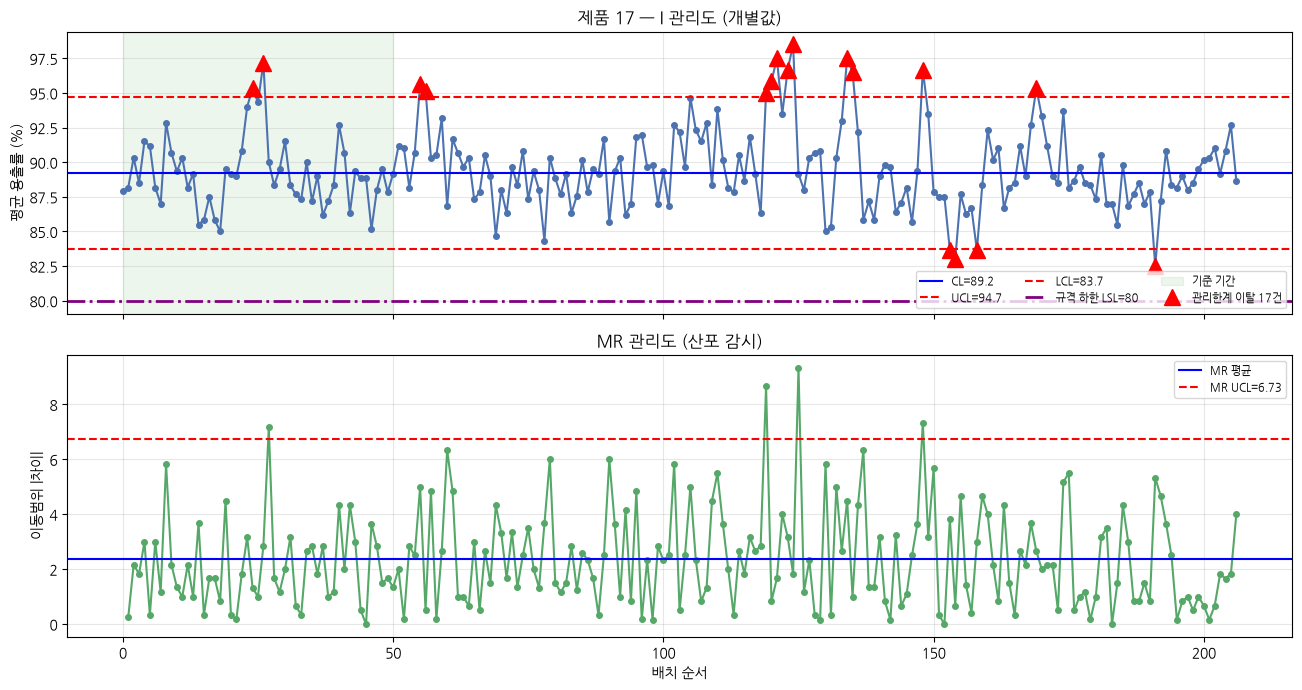

In [3]:
MR = np.abs(np.diff(base))
sigma_mr = MR.mean() / 1.128          # d2 상수 (n=2)
UCL_i, LCL_i = CL + 3 * sigma_mr, CL - 3 * sigma_mr
UCL_mr = 3.267 * np.abs(np.diff(base)).mean()      # D4 상수 (n=2)
mr_all = np.concatenate([[np.nan], np.abs(np.diff(x))])

fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].plot(x, "o-", ms=4, color="#4C72B0")
for v, c, l in [(CL, "blue", f"CL={CL:.1f}"), (UCL_i, "red", f"UCL={UCL_i:.1f}"), (LCL_i, "red", f"LCL={LCL_i:.1f}")]:
    ax[0].axhline(v, color=c, ls="--" if c == "red" else "-", lw=1.5, label=l)
ax[0].axhline(LSL, color="purple", ls="-.", lw=2, label=f"규격 하한 LSL={LSL}")
ax[0].axvspan(0, 50, color="green", alpha=0.07, label="기준 기간")
out = (x > UCL_i) | (x < LCL_i)
ax[0].plot(np.where(out)[0], x[out], "r^", ms=11, label=f"관리한계 이탈 {out.sum()}건")
ax[0].set_ylabel("평균 용출률 (%)"); ax[0].set_title(f"제품 {CODE} — I 관리도 (개별값)"); ax[0].legend(fontsize=8, ncol=3); ax[0].grid(alpha=0.3)

ax[1].plot(mr_all, "o-", ms=4, color="#55A868")
ax[1].axhline(np.nanmean(mr_all), color="blue", lw=1.5, label="MR 평균")
ax[1].axhline(UCL_mr, color="red", ls="--", lw=1.5, label=f"MR UCL={UCL_mr:.2f}")
ax[1].set_ylabel("이동범위 |차이|"); ax[1].set_xlabel("배치 순서"); ax[1].set_title("MR 관리도 (산포 감시)")
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. ⭐ Nelson 규칙 — 한계를 벗어나지 않아도 이상 신호
점 하나가 관리한계를 벗어나는 것(규칙 1)만이 신호가 아닙니다. **패턴**도 신호입니다.

| 규칙 | 내용 | 의미 |
|---|---|---|
| 1 | 1점이 3σ 밖 | 급격한 이상 |
| 2 | **연속 9점이 중심선 한쪽** | 평균 이동(shift) |
| 3 | 연속 6점이 계속 증가/감소 | 추세(trend), 공구 마모 등 |
| 5 | 연속 3점 중 2점이 2σ 밖 | 변동 증가 조짐 |
| 6 | 연속 5점 중 4점이 1σ 밖 | 평균의 작은 이동 |

규칙별 신호 건수:
  규칙 1:  17건
  규칙 2:   2건
  규칙 3:   1건
  규칙 5:  24건
  규칙 6:  34건


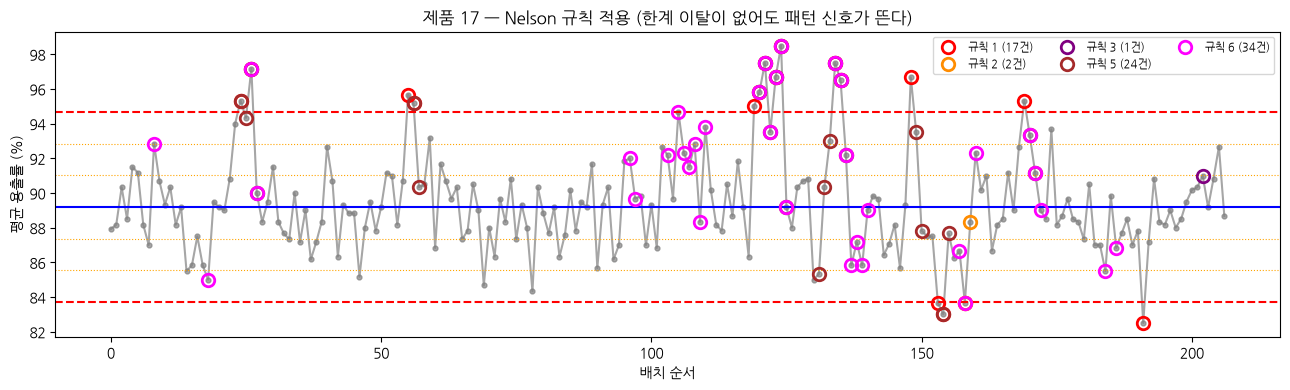

In [4]:
def nelson_rules(x, CL, sigma):
    n = len(x); z = (x - CL) / sigma
    flags = {k: np.zeros(n, bool) for k in [1, 2, 3, 5, 6]}
    flags[1] = np.abs(z) > 3
    for i in range(8, n):
        w = z[i-8:i+1]
        if np.all(w > 0) or np.all(w < 0): flags[2][i] = True
    for i in range(5, n):
        w = x[i-5:i+1]
        if np.all(np.diff(w) > 0) or np.all(np.diff(w) < 0): flags[3][i] = True
    for i in range(2, n):
        if (np.abs(z[i-2:i+1]) > 2).sum() >= 2: flags[5][i] = True
    for i in range(4, n):
        if (np.abs(z[i-4:i+1]) > 1).sum() >= 4: flags[6][i] = True
    return flags

flags = nelson_rules(x, CL, sigma_mr)
print("규칙별 신호 건수:")
for k, v in flags.items(): print(f"  규칙 {k}: {v.sum():3d}건")

plt.figure(figsize=(13, 4))
plt.plot(x, "o-", ms=3.5, color="gray", alpha=0.7)
plt.axhline(CL, color="blue"); plt.axhline(UCL_i, color="red", ls="--"); plt.axhline(LCL_i, color="red", ls="--")
for v in [1, 2]:
    plt.axhline(CL + v * sigma_mr, color="orange", ls=":", lw=0.8); plt.axhline(CL - v * sigma_mr, color="orange", ls=":", lw=0.8)
colors = {1: "red", 2: "darkorange", 3: "purple", 5: "brown", 6: "magenta"}
for k, v in flags.items():
    if v.sum(): plt.plot(np.where(v)[0], x[v], "o", ms=9, mfc="none", mec=colors[k], mew=2, label=f"규칙 {k} ({v.sum()}건)")
plt.ylabel("평균 용출률 (%)"); plt.xlabel("배치 순서"); plt.legend(fontsize=8, ncol=3)
plt.title(f"제품 {CODE} — Nelson 규칙 적용 (한계 이탈이 없어도 패턴 신호가 뜬다)"); plt.tight_layout(); plt.show()

## 4. 공정능력 — Cp · Cpk · Pp · Ppk
| 지수 | 수식 | 의미 |
|---|---|---|
| **Cp** | $(USL-LSL)/(6\sigma_{단기})$ | 공정의 **잠재** 능력 (중심이 맞다고 가정) |
| **Cpk** | $\min\left(\frac{USL-\mu}{3\sigma},\frac{\mu-LSL}{3\sigma}\right)$ | **중심 치우침까지 반영한 실제 능력** |
| **Pp / Ppk** | 같은 식에 **장기 전체 표준편차** 사용 | 장기 성능 (PPQ·APR 보고용) |

| Cpk | 평가 |
|---|---|
| ≥ 1.33 | 충분 (일반적 요구 수준) |
| 1.00~1.33 | 보통 — 개선 권고 |
| < 1.00 | 부족 — 부적합 발생 불가피 |

> 한쪽 규격만 있는 경우(용출률은 하한만)는 **Cpl**(하한 기준)만 계산합니다.

,제품,배치수,평균,단기σ,장기σ,Cpl,Ppl,Cpk,Ppk
0,17,207,89.447,2.090,2.862,1.506,1.100,1.506,1.100
1,23,187,89.161,2.082,2.737,1.467,1.116,1.467,1.116
2,13,131,91.535,2.067,2.578,1.860,1.491,1.860,1.491
3,1,95,94.131,1.766,2.772,2.668,1.699,2.668,1.699
4,21,68,92.819,2.472,2.322,1.728,1.840,1.728,1.840
5,15,64,88.124,2.120,2.499,1.278,1.084,1.278,1.084


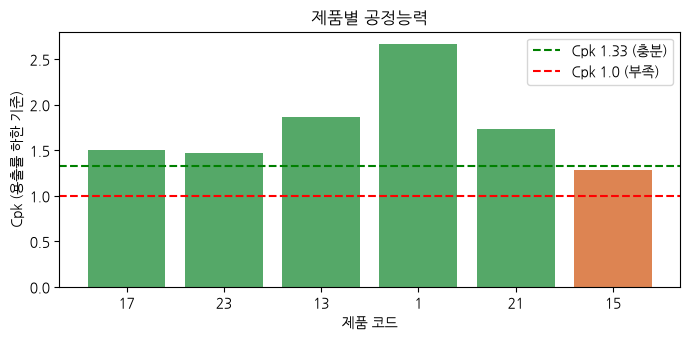

In [5]:
def capability(x, LSL=None, USL=None, sigma=None):
    mu = x.mean()
    s_long = x.std(ddof=1)
    s_short = sigma if sigma is not None else np.abs(np.diff(x)).mean() / 1.128
    r = {"평균": mu, "단기σ": s_short, "장기σ": s_long}
    if LSL is not None and USL is not None:
        r["Cp"] = (USL - LSL) / (6 * s_short); r["Pp"] = (USL - LSL) / (6 * s_long)
    if LSL is not None: r["Cpl"] = (mu - LSL) / (3 * s_short); r["Ppl"] = (mu - LSL) / (3 * s_long)
    if USL is not None: r["Cpu"] = (USL - mu) / (3 * s_short)
    r["Cpk"] = min([v for k, v in r.items() if k in ("Cpl", "Cpu")])
    r["Ppk"] = r.get("Ppl", np.nan)
    return r

rows = []
for c in df.code.value_counts().head(6).index:
    v = df[df.code == c]["dissolution_av"].values
    cap = capability(v, LSL=LSL)
    rows.append({"제품": c, "배치수": len(v), **{k: round(val, 3) for k, val in cap.items()}})
cap_df = pd.DataFrame(rows)
display(cap_df)

plt.figure(figsize=(7, 3.5))
plt.bar(cap_df["제품"].astype(str), cap_df["Cpk"], color=["#55A868" if v >= 1.33 else "#DD8452" if v >= 1 else "#C44E52" for v in cap_df["Cpk"]])
plt.axhline(1.33, color="green", ls="--", label="Cpk 1.33 (충분)"); plt.axhline(1.0, color="red", ls="--", label="Cpk 1.0 (부족)")
plt.xlabel("제품 코드"); plt.ylabel("Cpk (용출률 하한 기준)"); plt.legend(); plt.title("제품별 공정능력"); plt.tight_layout(); plt.show()

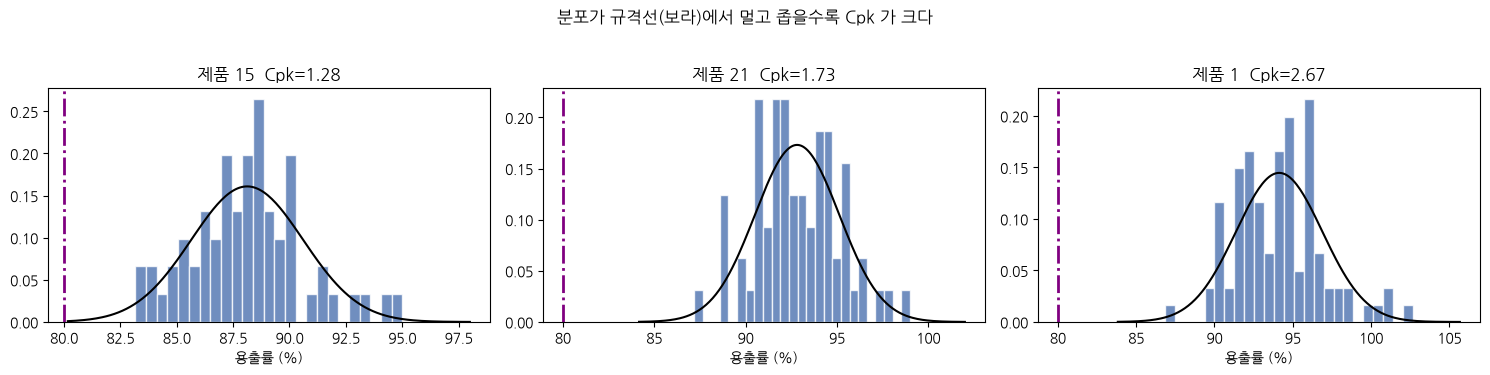

In [6]:
# 공정능력을 그림으로: 분포 vs 규격
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, c in zip(ax, cap_df.sort_values("Cpk")["제품"].values[[0, len(cap_df)//2, -1]]):
    v = df[df.code == c]["dissolution_av"].values
    cap = capability(v, LSL=LSL)
    a.hist(v, bins=25, color="#4C72B0", alpha=0.8, edgecolor="white", density=True)
    xs = np.linspace(v.min() - 3, v.max() + 3, 200)
    a.plot(xs, stats.norm.pdf(xs, v.mean(), v.std()), "k-", lw=1.5)
    a.axvline(LSL, color="purple", ls="-.", lw=2)
    a.set_title(f"제품 {c}  Cpk={cap['Cpk']:.2f}"); a.set_xlabel("용출률 (%)")
plt.suptitle("분포가 규격선(보라)에서 멀고 좁을수록 Cpk 가 크다", y=1.03); plt.tight_layout(); plt.show()

## 5. CUSUM · EWMA — 작은 변화를 빨리 잡기
Shewhart(3σ) 관리도는 **1σ 정도의 작은 평균 이동**을 잘 못 잡습니다. 누적 통계량을 쓰면 훨씬 민감해집니다.
- **CUSUM**: 목표값과의 편차를 **누적**. $C^+_i=\max(0, C^+_{i-1}+(x_i-\mu_0)-k)$, 보통 $k=0.5\sigma$, 한계 $h=5\sigma$
- **EWMA**: 지수가중이동평균 $z_i=\lambda x_i+(1-\lambda)z_{i-1}$, 보통 $\lambda=0.2$

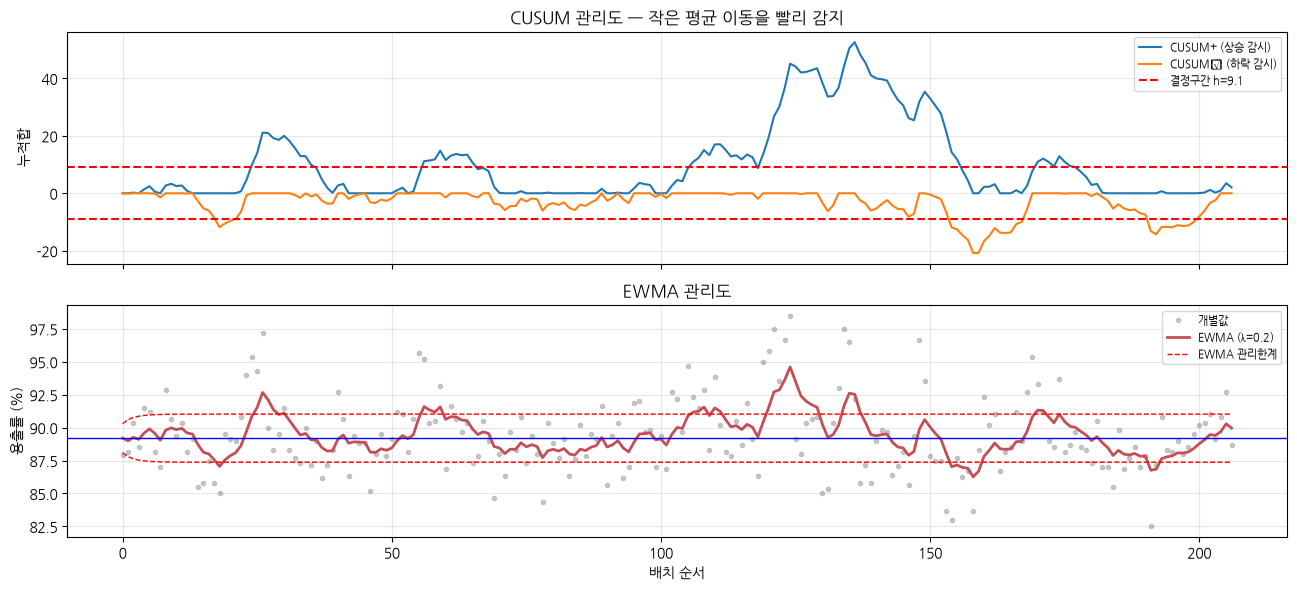

CUSUM 신호: 102건 / EWMA 신호: 40건 / Shewhart 신호: 17건
→ 민감한 기법일수록 신호가 많습니다. 민감도와 오경보는 항상 거래 관계이며, 목적에 맞게 k·h·λ 를 조정합니다.


In [7]:
k, h, lam = 0.5 * sigma_mr, 5 * sigma_mr, 0.2
cp = np.zeros(len(x)); cm = np.zeros(len(x))
for i in range(1, len(x)):
    cp[i] = max(0, cp[i-1] + (x[i] - CL) - k)
    cm[i] = min(0, cm[i-1] + (x[i] - CL) + k)
z = np.zeros(len(x)); z[0] = CL
for i in range(1, len(x)):
    z[i] = lam * x[i] + (1 - lam) * z[i-1]
i_ = np.arange(1, len(x) + 1)
ew_sd = sigma_mr * np.sqrt(lam / (2 - lam) * (1 - (1 - lam) ** (2 * i_)))

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(cp, label="CUSUM+ (상승 감시)"); ax[0].plot(cm, label="CUSUM− (하락 감시)")
ax[0].axhline(h, color="red", ls="--", label=f"결정구간 h={h:.1f}"); ax[0].axhline(-h, color="red", ls="--")
ax[0].set_ylabel("누적합"); ax[0].legend(fontsize=8); ax[0].set_title("CUSUM 관리도 — 작은 평균 이동을 빨리 감지"); ax[0].grid(alpha=0.3)
ax[1].plot(x, "o", ms=3, alpha=0.4, color="gray", label="개별값")
ax[1].plot(z, "-", color="#C44E52", lw=2, label="EWMA (λ=0.2)")
ax[1].plot(CL + 3 * ew_sd, "r--", lw=1); ax[1].plot(CL - 3 * ew_sd, "r--", lw=1, label="EWMA 관리한계")
ax[1].axhline(CL, color="blue", lw=1)
ax[1].set_ylabel("용출률 (%)"); ax[1].set_xlabel("배치 순서"); ax[1].legend(fontsize=8); ax[1].set_title("EWMA 관리도"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"CUSUM 신호: {int(((cp>h)|(cm<-h)).sum())}건 / EWMA 신호: {int(((z>CL+3*ew_sd)|(z<CL-3*ew_sd)).sum())}건 / Shewhart 신호: {int(out.sum())}건")
print("→ 민감한 기법일수록 신호가 많습니다. 민감도와 오경보는 항상 거래 관계이며, 목적에 맞게 k·h·λ 를 조정합니다.")

## 6. ⭐ 다변량 SPC — 변수 하나씩 보면 놓치는 이상
변수가 20개면 관리도도 20개입니다. 문제는 **각 변수는 정상인데 조합이 비정상**인 경우입니다.
- **Hotelling T²**: 평균 벡터로부터의 거리 (변수 간 상관을 공분산으로 보정)
- **PCA 기반 Q 통계(SPE)**: 주성분 모델로 설명되지 않는 잔차 → **새로운 유형의 이상**

> 제약 공정의 NIR/Raman 스펙트럼, 다변량 센서 데이터에 쓰이는 표준 기법입니다 (PAT, 예제 09).

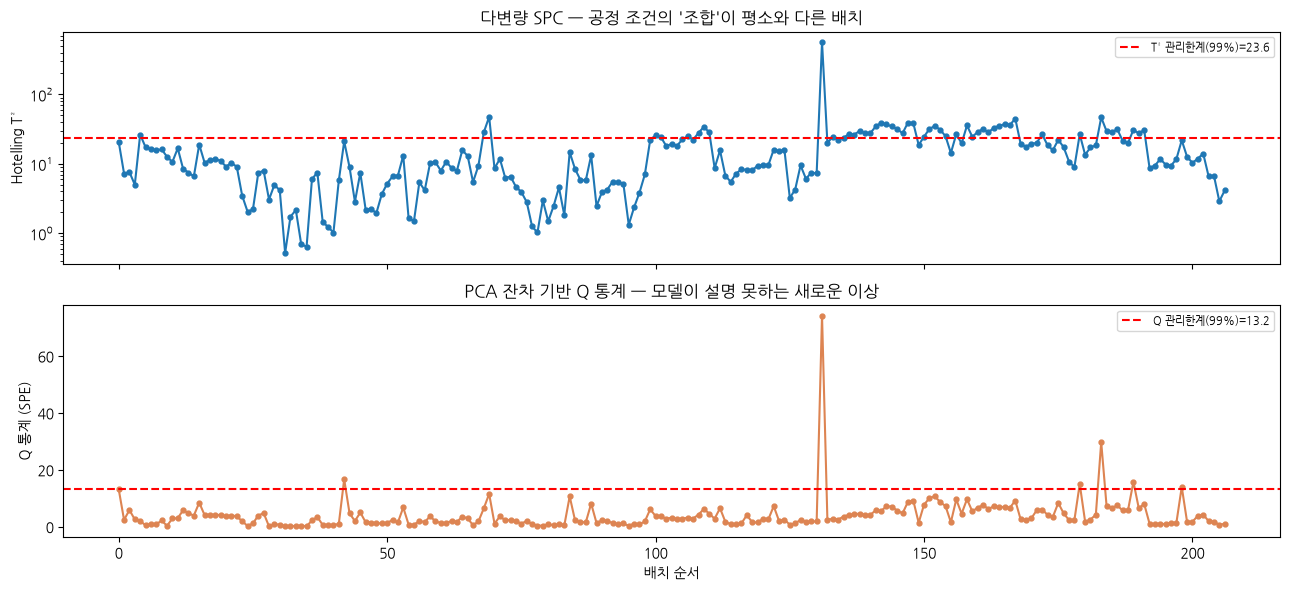

T² 신호 50건(24%), Q 신호 6건(3%) / 단변량 Shewhart 신호 17건

⚠️ 경보율이 기대치(1%)보다 훨씬 높습니다. 두 가지 중 하나입니다:
   ① 기준 기간이 공정을 대표하지 못함(원료 로트·설비 변경 포함) → 기준 기간 재설정
   ② 공정이 실제로 기준 기간 이후 변했음 → 공정 조사 필요
   경보가 너무 많으면 현장이 경보를 무시하게 됩니다(경보 피로) — 한계 설정은 운영팀과 합의해야 합니다.


In [8]:
VARS = ["main_CompForce mean", "main_CompForce_sd", "tbl_fill_mean", "tbl_speed_mean",
        "SREL_production_mean", "stiffness_mean", "ejection_mean", "tbl_av_hardness"]
M = s[VARS].fillna(s[VARS].median())
base_idx = np.arange(100)        # 다변량 한계는 변수가 많아 기준 기간을 더 길게 잡습니다
mu_v, S = M.iloc[base_idx].mean().values, np.cov(M.iloc[base_idx].values, rowvar=False)
Sinv = np.linalg.pinv(S)
d = M.values - mu_v
T2 = np.einsum("ij,jk,ik->i", d, Sinv, d)
pv, m_ = len(VARS), len(base_idx)
UCL_T2 = pv * (m_ + 1) * (m_ - 1) / (m_ * (m_ - pv)) * stats.f.ppf(0.99, pv, m_ - pv)

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(M.iloc[base_idx]); Z = sc.transform(M)
pca = PCA(n_components=3).fit(Z[base_idx])
Q = ((Z - pca.inverse_transform(pca.transform(Z))) ** 2).sum(1)
UCL_Q = np.percentile(Q[base_idx], 99)

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(T2, "o-", ms=3.5); ax[0].axhline(UCL_T2, color="red", ls="--", label=f"T² 관리한계(99%)={UCL_T2:.1f}")
ax[0].set_ylabel("Hotelling T²"); ax[0].set_yscale("log"); ax[0].legend(fontsize=8); ax[0].set_title("다변량 SPC — 공정 조건의 '조합'이 평소와 다른 배치")
ax[1].plot(Q, "o-", ms=3.5, color="#DD8452"); ax[1].axhline(UCL_Q, color="red", ls="--", label=f"Q 관리한계(99%)={UCL_Q:.1f}")
ax[1].set_ylabel("Q 통계 (SPE)"); ax[1].set_xlabel("배치 순서"); ax[1].legend(fontsize=8); ax[1].set_title("PCA 잔차 기반 Q 통계 — 모델이 설명 못하는 새로운 이상")
plt.tight_layout(); plt.show()
n_t2, n_q = int((T2 > UCL_T2).sum()), int((Q > UCL_Q).sum())
print(f"T² 신호 {n_t2}건({n_t2/len(T2):.0%}), Q 신호 {n_q}건({n_q/len(Q):.0%}) / 단변량 Shewhart 신호 {int(out.sum())}건")
print("\n⚠️ 경보율이 기대치(1%)보다 훨씬 높습니다. 두 가지 중 하나입니다:")
print("   ① 기준 기간이 공정을 대표하지 못함(원료 로트·설비 변경 포함) → 기준 기간 재설정")
print("   ② 공정이 실제로 기준 기간 이후 변했음 → 공정 조사 필요")
print("   경보가 너무 많으면 현장이 경보를 무시하게 됩니다(경보 피로) — 한계 설정은 운영팀과 합의해야 합니다.")

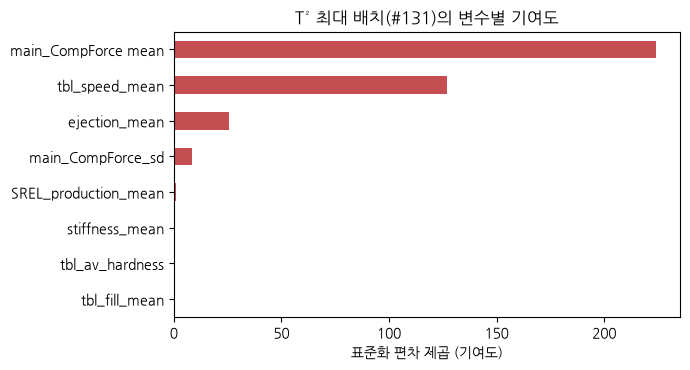

→ 가장 기여도가 큰 변수부터 조사하면 일탈 조사(Deviation investigation) 시간을 단축할 수 있습니다.


In [9]:
# ⭐ 기여도 분석(Contribution plot) — "왜 T² 가 튀었나?"를 설명해야 조치가 가능하다
worst = int(np.argmax(T2))
contrib = pd.Series(((M.values[worst] - mu_v) / np.sqrt(np.diag(S))) ** 2, index=VARS).sort_values()
contrib.plot.barh(figsize=(7, 3.8), color="#C44E52")
plt.xlabel("표준화 편차 제곱 (기여도)"); plt.title(f"T² 최대 배치(#{worst})의 변수별 기여도"); plt.tight_layout(); plt.show()
print("→ 가장 기여도가 큰 변수부터 조사하면 일탈 조사(Deviation investigation) 시간을 단축할 수 있습니다.")

## 7. SPC 와 AI 는 어떻게 역할을 나누나
| | 전통 SPC | AI / 머신러닝 |
|---|---|---|
| 가정 | 정규분포, 선형, 독립 | 가정이 적음 (비선형·상호작용 학습) |
| 변수 수 | 소수 (단변량 중심) | 수십~수백 개 |
| 설명력 | 매우 높음 (규제 친화) | 별도 설명 기법 필요 (SHAP) |
| 데이터 요구 | 적음 | 많음 |
| 역할 | **공정 관리의 법적·표준 기반** | SPC 가 놓치는 복합 패턴 탐지, 사전 예측 |

> **권장 구성**: ① SPC(관리도·Cpk)로 기본 감시 → ② 다변량 SPC(T²·Q)로 조합 이상 감지 →
> ③ AI 이상탐지·예측 모델로 조기 경보(예제 05·06) → ④ 모든 경보는 **일탈 조사 절차**로 연결

## 🧪 LLM 코딩 과제
```
pandas 데이터프레임 df(제약 정제 1005배치, code=제품코드, start_date, dissolution_av 열 포함)가 있어.
제품 코드 23에 대해 I-MR 관리도를 그리고, 초기 40배치를 기준 기간으로 관리한계를 계산해줘.
그리고 Cpk(규격 하한 80 기준)를 계산해서 제목에 표시해줘. 한글 주석을 달아줘.
```

In [10]:
# ✏️ LLM 코드 붙여넣기

## ✅ 정리
| 개념 | 핵심 |
|---|---|
| 관리한계 vs 규격 | 공정 기준 vs 제품 기준 — **절대 혼동 금지** |
| I-MR 관리도 | 배치 공정의 표준. σ 는 $\overline{MR}/1.128$ |
| Nelson 규칙 | 한계 이탈이 없어도 **패턴**이 이상 신호 |
| Cp / Cpk | Cpk 가 실제 능력. 1.33 이상이 일반적 목표 |
| CUSUM / EWMA | 작은 평균 이동을 조기 감지 |
| 다변량 SPC | T²(조합 이상) + Q(새 유형 이상) + **기여도 분석**으로 원인 좁히기 |

➡️ **다음 예제 04**: 10초 단위 **공정 시계열 데이터**에서 특성을 뽑아 품질을 예측합니다